# Klasifikasi Citra Emosi Wajah Menggunakan CNN
**Praktikum:** Klasifikasi Citra Emosi Wajah menggunakan Convolutional Neural Network (CNN) dengan Dashboard Streamlit
**Dataset:** Facial Emotion Recognition (FER2013) - Kaggle (`fahadullaha/facial-emotion-recognition-dataset`)

**Tujuan:**
1. Memahami dataset citra emosi wajah dari Kaggle
2. Melakukan eksplorasi (EDA) dan pra-pemrosesan data citra
3. Membangun model klasifikasi citra dengan CNN
4. Mengevaluasi model (Accuracy, Precision, Recall, F1-Score)
5. Menampilkan hasil analisis & prediksi lewat dashboard Streamlit

> Notebook ini menyimpan semua keluaran ke folder `output/` dengan nama file yang sama seperti versi sebelumnya, jadi dashboard Streamlit lama tetap bisa membacanya.

In [1]:
# Hapus tanda '#' di bawah ini bila library belum terpasang
%pip install tensorflow numpy matplotlib scikit-learn pillow pandas seaborn opencv-python streamlit

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, json, time, random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import cv2
from PIL import Image

from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

# ===================== KONFIGURASI =====================
BASE_DIR = r"D:/Downloads/coba emosi wjaah/processed_data"   # folder berisi 7 subfolder kelas
IMG_SIZE = (48, 48)
BATCH    = 64
EPOCHS   = 60
LR       = 1e-3
SEED     = 42
OUT_DIR  = "output"
# =======================================================

os.makedirs(OUT_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

print("TensorFlow :", tf.__version__)
print("GPU        :", tf.config.list_physical_devices("GPU") or "tidak ada (pakai CPU)")

TensorFlow : 2.22.0-rc0
GPU        : tidak ada (pakai CPU)


## Langkah 1 - Pengambilan dan Pemahaman Dataset
Dataset dibaca per folder kelas. Nama folder = label emosi.

In [3]:
VALID_EXT = (".jpg", ".jpeg", ".png", ".bmp")

class_names = sorted(d for d in os.listdir(BASE_DIR)
                     if os.path.isdir(os.path.join(BASE_DIR, d)))
num_classes = len(class_names)
print("Folder kelas yang ditemukan:", class_names)
assert num_classes == 7, (
    f"Ditemukan {num_classes} folder, seharusnya 7 kelas emosi. "
    "Pastikan BASE_DIR langsung berisi folder angry, disgust, fear, happy, neutral, sad, surprise "
    "(bukan folder train/test di atasnya).")

file_paths, labels = [], []
for idx, cname in enumerate(class_names):
    folder = os.path.join(BASE_DIR, cname)
    for f in sorted(os.listdir(folder)):
        if f.lower().endswith(VALID_EXT):
            file_paths.append(os.path.join(folder, f))
            labels.append(idx)

file_paths = np.array(file_paths)
labels     = np.array(labels, dtype=np.int32)

print("Jumlah kelas :", num_classes)
print("Total gambar :", len(file_paths))

Folder kelas yang ditemukan: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Jumlah kelas : 7
Total gambar : 49779


## Langkah 2 - Eksplorasi Data (EDA)

,Emotion,Total Images
0,angry,5920
1,disgust,5920
2,fear,5920
3,happy,11398
4,neutral,8166
5,sad,6535
6,surprise,5920


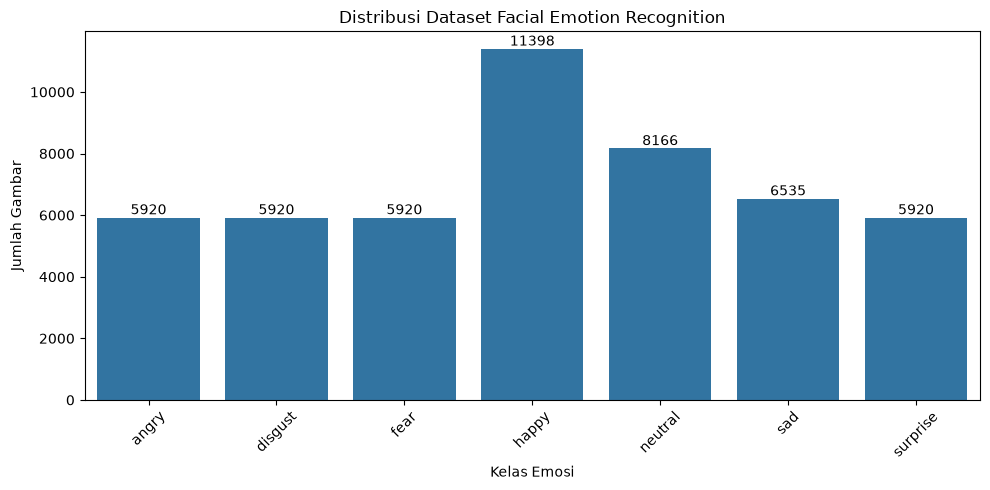

Kelas terbanyak : happy (11398)
Kelas tersedikit: angry (5920)
Rasio terbanyak:tersedikit = 1.9x -> ADA class imbalance (ditangani dengan class_weight)


In [4]:
# Distribusi jumlah gambar per kelas
counts = np.bincount(labels, minlength=num_classes)
df_distribution = pd.DataFrame({"Emotion": class_names, "Total Images": counts})
display(df_distribution)
df_distribution.to_csv(os.path.join(OUT_DIR, "class_distribution.csv"), index=False)

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=df_distribution, x="Emotion", y="Total Images")
for c in ax.containers:
    ax.bar_label(c)
plt.title("Distribusi Dataset Facial Emotion Recognition")
plt.xlabel("Kelas Emosi"); plt.ylabel("Jumlah Gambar")
plt.xticks(rotation=45); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "1_class_distribution.png"), dpi=150)
plt.show()

# Cek ketidakseimbangan kelas
ratio = counts.max() / counts.min()
print(f"Kelas terbanyak : {class_names[counts.argmax()]} ({counts.max()})")
print(f"Kelas tersedikit: {class_names[counts.argmin()]} ({counts.min()})")
print(f"Rasio terbanyak:tersedikit = {ratio:.1f}x ->",
      "ADA class imbalance (ditangani dengan class_weight)" if ratio > 1.5 else "relatif seimbang")

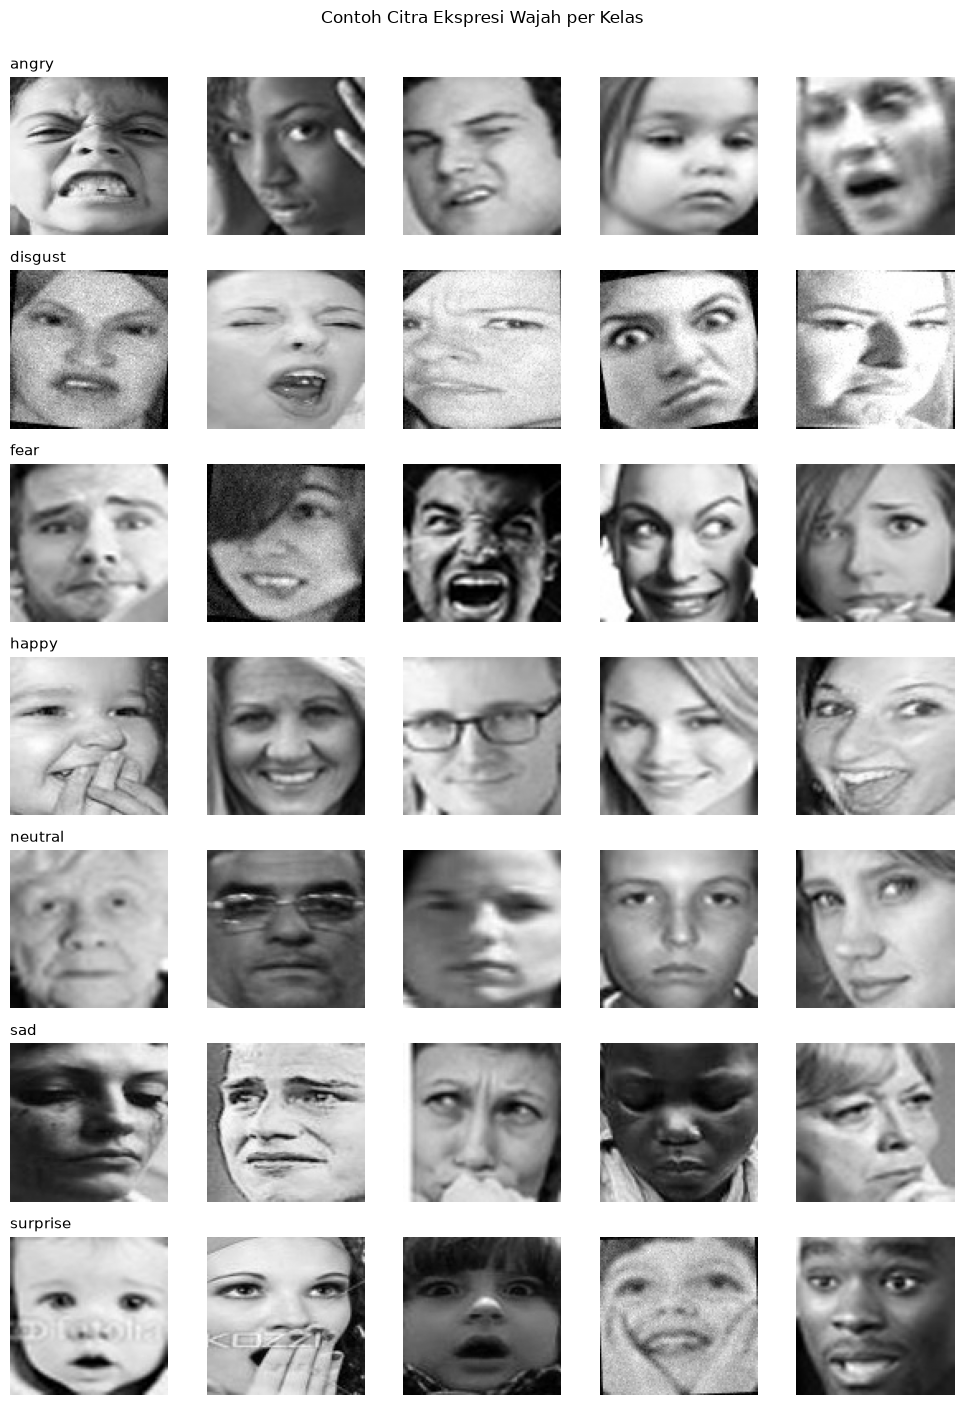

In [5]:
# Contoh gambar tiap kelas (5 gambar acak per kelas)
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(num_classes, 5, figsize=(10, 2 * num_classes))
for r, cname in enumerate(class_names):
    pool = file_paths[labels == r]
    for c, p in enumerate(rng.choice(pool, size=5, replace=False)):
        axes[r, c].imshow(Image.open(p).convert("L"), cmap="gray")
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(cname, loc="left", fontsize=11)
plt.suptitle("Contoh Citra Ekspresi Wajah per Kelas", y=1.0)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "2_sample_images.png"), dpi=150)
plt.show()

In [6]:
# Ukuran & mode warna gambar (sampel maks. 200 gambar per kelas)
size_counter, mode_counter = Counter(), Counter()
for r in range(num_classes):
    pool = file_paths[labels == r]
    for p in rng.choice(pool, size=min(200, len(pool)), replace=False):
        with Image.open(p) as im:
            size_counter[im.size] += 1
            mode_counter[im.mode] += 1
print("Ukuran gambar (lebar, tinggi):", dict(size_counter))
print("Mode warna                    :", dict(mode_counter), "(L = grayscale, RGB = berwarna)")

Ukuran gambar (lebar, tinggi): {(96, 96): 1400}
Mode warna                    : {'RGB': 1400} (L = grayscale, RGB = berwarna)


## Langkah 3 - Pra-Pemrosesan Data
- **Resize** semua gambar ke 48x48 piksel dan dibaca sebagai **grayscale**
- **Pembagian data 80% latih / 20% validasi** secara *stratified* (proporsi tiap kelas sama di kedua bagian) dan dicek tidak ada gambar yang muncul di kedua set
- **Normalisasi piksel 0-1** dilakukan oleh layer `Rescaling(1/255)` di dalam model (lihat Langkah 4)
- **Label one-hot** (`label_mode categorical`)
- **Augmentasi** (flip, rotasi, zoom, geser, kontras) juga di dalam model, aktif hanya saat training

In [7]:
train_paths, val_paths, train_labels, val_labels = train_test_split(
    file_paths, labels, test_size=0.2, stratify=labels, random_state=SEED)

# Pastikan TIDAK ADA kebocoran data antara latih dan validasi
assert len(set(train_paths) & set(val_paths)) == 0, "Ada gambar yang sama di train dan validasi!"

print(f"Data latih     : {len(train_paths)} ({len(train_paths)/len(file_paths):.0%})")
print(f"Data validasi  : {len(val_paths)} ({len(val_paths)/len(file_paths):.0%})")

df_split = pd.DataFrame({
    "Emotion": class_names,
    "Train": np.bincount(train_labels, minlength=num_classes),
    "Validation": np.bincount(val_labels, minlength=num_classes),
})
display(df_split)

with open(os.path.join(OUT_DIR, "dataset_summary.json"), "w") as f:
    json.dump({
        "num_classes": num_classes,
        "class_names": class_names,
        "total_images": int(len(file_paths)),
        "train_images": int(len(train_paths)),
        "val_images": int(len(val_paths)),
        "split": "80/20 stratified",
        "image_size": list(IMG_SIZE),
        "color_mode": "grayscale",
    }, f, indent=4)

Data latih     : 39823 (80%)
Data validasi  : 9956 (20%)


,Emotion,Train,Validation
0,angry,4736,1184
1,disgust,4736,1184
2,fear,4736,1184
3,happy,9118,2280
4,neutral,6533,1633
5,sad,5228,1307
6,surprise,4736,1184


In [8]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=1, expand_animations=False)   # grayscale
    img = tf.image.resize(img, IMG_SIZE, antialias=True)                  # nilai tetap 0-255
    img.set_shape((IMG_SIZE[0], IMG_SIZE[1], 1))
    return img, tf.one_hot(label, num_classes)

def make_dataset(paths, lbls, training):
    ds = tf.data.Dataset.from_tensor_slices((paths, lbls))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load_image, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds   = make_dataset(val_paths,   val_labels,   training=False)   # urutan tetap = val_labels

# Bukti normalisasi: sebelum vs sesudah Rescaling
x_batch, y_batch = next(iter(train_ds))
print("Bentuk batch gambar:", x_batch.shape, "| label one-hot:", y_batch.shape)
print("Rentang piksel input model     :", float(tf.reduce_min(x_batch)), "-", float(tf.reduce_max(x_batch)))
x_norm = layers.Rescaling(1./255)(x_batch)
print("Rentang setelah Rescaling(1/255):", float(tf.reduce_min(x_norm)), "-", float(tf.reduce_max(x_norm)))

Bentuk batch gambar: (64, 48, 48, 1) | label one-hot: (64, 7)
Rentang piksel input model     : 0.0 - 255.00003051757812
Rentang setelah Rescaling(1/255): 0.0 - 1.000000238418579


## Langkah 4 - Pembangunan Model CNN
**Arsitektur:** 4 blok konvolusi (masing-masing 2x Conv2D + BatchNorm + MaxPooling + Dropout) -> Flatten -> Dense 256 -> Softmax 7 kelas.

| Parameter | Nilai |
|---|---|
| Input | 48x48x1 (grayscale, 0-255; dinormalisasi di dalam model) |
| Filter per blok | 32 -> 64 -> 128 -> 256 |
| Aktivasi hidden / output | ReLU / Softmax |
| Optimizer / Learning rate | Adam / 0.001 (turun otomatis dengan ReduceLROnPlateau) |
| Loss | Categorical Crossentropy |
| Batch size / Epoch maks. | 64 / 60 (dengan EarlyStopping) |

> **Penting untuk dashboard:** model ini menerima piksel **0-255** karena `Rescaling(1/255)` sudah ada di dalam model. Jangan membagi 255 lagi di `app.py`.

In [9]:
def build_model(num_classes):
    inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 1), name="input_gray")

    # --- Augmentasi (hanya aktif saat training) ---
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(0.08)(x)
    x = layers.RandomZoom(0.10)(x)
    x = layers.RandomTranslation(0.08, 0.08)(x)
    x = layers.RandomContrast(0.20)(x)

    # --- Normalisasi piksel 0-255 -> 0-1 ---
    x = layers.Rescaling(1./255, name="rescaling")(x)

    blocks = [(32, 0.25), (64, 0.25), (128, 0.30), (256, 0.35)]
    for i, (filters, drop) in enumerate(blocks, start=1):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu", name=f"conv{i}_1")(x)
        x = layers.BatchNormalization()(x)
        last = (i == len(blocks))
        x = layers.Conv2D(filters, 3, padding="same", activation="relu",
                          name="conv_last" if last else f"conv{i}_2")(x)   # dipakai Grad-CAM
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D(2)(x)
        x = layers.Dropout(drop)(x)

    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="emotion")(x)
    return models.Model(inputs, outputs, name="cnn_emosi_wajah")

model = build_model(num_classes)
model.compile(optimizer=Adam(learning_rate=LR),
              loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "cnn_emosi_wajah"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_gray (InputLayer)         │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 48, 48, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 48, 48, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 48, 48, 1)      │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_1 (Conv2D)                │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_2 (Conv2D)                │ (None, 48, 48, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_1 (Conv2D)                │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_2 (Conv2D)                │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3_1 (Conv2D)                │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 1,768,423 (6.75 MB)

 Trainable params: 1,765,991 (6.74 MB)

 Non-trainable params: 2,432 (9.50 KB)

In [10]:
# Class weight untuk menangani ketidakseimbangan kelas (dihitung dari data latih saja)
cnt_train = np.bincount(train_labels, minlength=num_classes)
class_weight = {i: len(train_labels) / (num_classes * cnt_train[i]) for i in range(num_classes)}
print("Class weight:", {class_names[i]: round(w, 2) for i, w in class_weight.items()})

best_model_path  = os.path.join(OUT_DIR, "facial_emotion_cnn_best.keras")
final_model_path = os.path.join(OUT_DIR, "final_facial_emotion_cnn.keras")

callbacks = [
    EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True),
    ModelCheckpoint(best_model_path, monitor="val_loss", save_best_only=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1),
]

Class weight: {'angry': np.float64(1.2), 'disgust': np.float64(1.2), 'fear': np.float64(1.2), 'happy': np.float64(0.62), 'neutral': np.float64(0.87), 'sad': np.float64(1.09), 'surprise': np.float64(1.2)}


In [11]:
start = time.time()
history_obj = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                        callbacks=callbacks, class_weight=class_weight)
training_time = time.time() - start
history = {k: [float(v) for v in vals] for k, vals in history_obj.history.items()}

print(f"Waktu training: {training_time:.1f} detik | epoch dijalankan: {len(history['loss'])}")
with open(os.path.join(OUT_DIR, "training_history.json"), "w") as f:
    json.dump(history, f)

Epoch 1/60


c:\Users\Axioo\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


623/623 ━━━━━━━━━━━━━━━━━━━━ 237s 372ms/step - accuracy: 0.2460 - loss: 2.0827 - val_accuracy: 0.3975 - val_loss: 1.6226 - learning_rate: 0.0010
Epoch 2/60
623/623 ━━━━━━━━━━━━━━━━━━━━ 188s 301ms/step - accuracy: 0.3993 - loss: 1.6134 - val_accuracy: 0.4453 - val_loss: 1.4707 - learning_rate: 0.0010
Epoch 3/60
623/623 ━━━━━━━━━━━━━━━━━━━━ 184s 295ms/step - accuracy: 0.4653 - loss: 1.4529 - val_accuracy: 0.5011 - val_loss: 1.3302 - learning_rate: 0.0010
Epoch 4/60
623/623 ━━━━━━━━━━━━━━━━━━━━ 191s 306ms/step - accuracy: 0.5003 - loss: 1.3727 - val_accuracy: 0.4971 - val_loss: 1.3794 - learning_rate: 0.0010
Epoch 5/60
623/623 ━━━━━━━━━━━━━━━━━━━━ 195s 313ms/step - accuracy: 0.5298 - loss: 1.3036 - val_accuracy: 0.5772 - val_loss: 1.1224 - learning_rate: 0.0010
Epoch 6/60
623/623 ━━━━━━━━━━━━━━━━━━━━ 191s 306ms/step - accuracy: 0.5468 - loss: 1.2576 - val_accuracy: 0.4726 - val_loss: 1.5288 - learning_rate: 0.0010
Epoch 7/60
623/623 ━━━━━━━━━━━━━━━━━━━━ 192s 308ms/step - accuracy: 0.5671 

## Langkah 5 - Evaluasi Model

In [12]:
y_prob = model.predict(val_ds, verbose=0)
y_true = val_labels
y_pred = np.argmax(y_prob, axis=1)

accuracy  = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
recall    = recall_score(y_true, y_pred, average="weighted", zero_division=0)
f1        = f1_score(y_true, y_pred, average="weighted", zero_division=0)

metrics_df = pd.DataFrame({"Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
                           "Score": [accuracy, precision, recall, f1]})
display(metrics_df)
print("(Precision/Recall/F1 = rata-rata tertimbang (weighted) seluruh kelas)")
print(f"Macro F1 (tiap kelas dianggap sama penting): {f1_score(y_true, y_pred, average='macro'):.4f}")

metrics_df.to_csv(os.path.join(OUT_DIR, "evaluation_metrics.csv"), index=False)
with open(os.path.join(OUT_DIR, "metrics.json"), "w") as f:
    json.dump({"accuracy": float(accuracy), "precision": float(precision),
               "recall": float(recall), "f1_score": float(f1),
               "macro_f1": float(f1_score(y_true, y_pred, average="macro")),
               "training_time_sec": float(training_time)}, f, indent=4)

,Metric,Score
0,Accuracy,0.652772
1,Precision,0.668313
2,Recall,0.652772
3,F1-Score,0.651730


(Precision/Recall/F1 = rata-rata tertimbang (weighted) seluruh kelas)
Macro F1 (tiap kelas dianggap sama penting): 0.6329


In [13]:
report = classification_report(y_true, y_pred, labels=np.arange(num_classes),
                               target_names=class_names, output_dict=True, zero_division=0)
df_report = pd.DataFrame(report).transpose()
display(df_report.round(3))
df_report.to_csv(os.path.join(OUT_DIR, "classification_report.csv"))

per_class_f1 = df_report.loc[class_names, "f1-score"]
print(f"Kelas paling mudah dikenali: {per_class_f1.idxmax()} (F1 = {per_class_f1.max():.2f})")
print(f"Kelas paling sulit dikenali : {per_class_f1.idxmin()} (F1 = {per_class_f1.min():.2f})")

,precision,recall,f1-score,support
angry,0.592,0.517,0.552,1184.000
disgust,0.617,0.877,0.725,1184.000
fear,0.438,0.553,0.489,1184.000
happy,0.913,0.778,0.840,2280.000
neutral,0.677,0.502,0.577,1633.000
sad,0.566,0.476,0.517,1307.000
surprise,0.656,0.826,0.731,1184.000
accuracy,0.653,0.653,0.653,0.653
macro avg,0.637,0.647,0.633,9956.000
weighted avg,0.668,0.653,0.652,9956.000


Kelas paling mudah dikenali: happy (F1 = 0.84)
Kelas paling sulit dikenali : fear (F1 = 0.49)


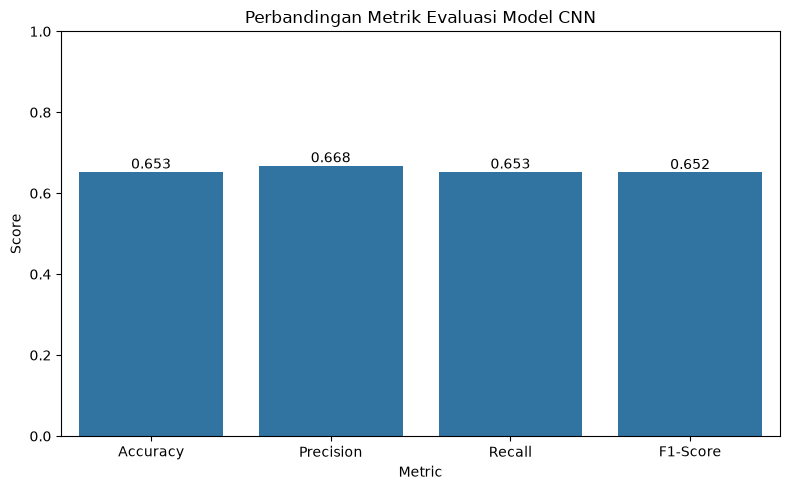

In [14]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(data=metrics_df, x="Metric", y="Score")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f")
plt.ylim(0, 1); plt.title("Perbandingan Metrik Evaluasi Model CNN")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "5_evaluation_metrics.png"), dpi=150)
plt.show()

**Cara membaca hasil:** akurasi tinggi berarti model mengenali emosi dengan baik secara keseluruhan; F1-score tinggi berarti precision dan recall seimbang. Bandingkan F1 antar kelas di tabel di atas: kelas seperti *disgust* dan *fear* umumnya paling sulit pada FER2013 karena datanya sedikit dan ekspresinya mirip emosi lain.

## Langkah 6 - Visualisasi Hasil

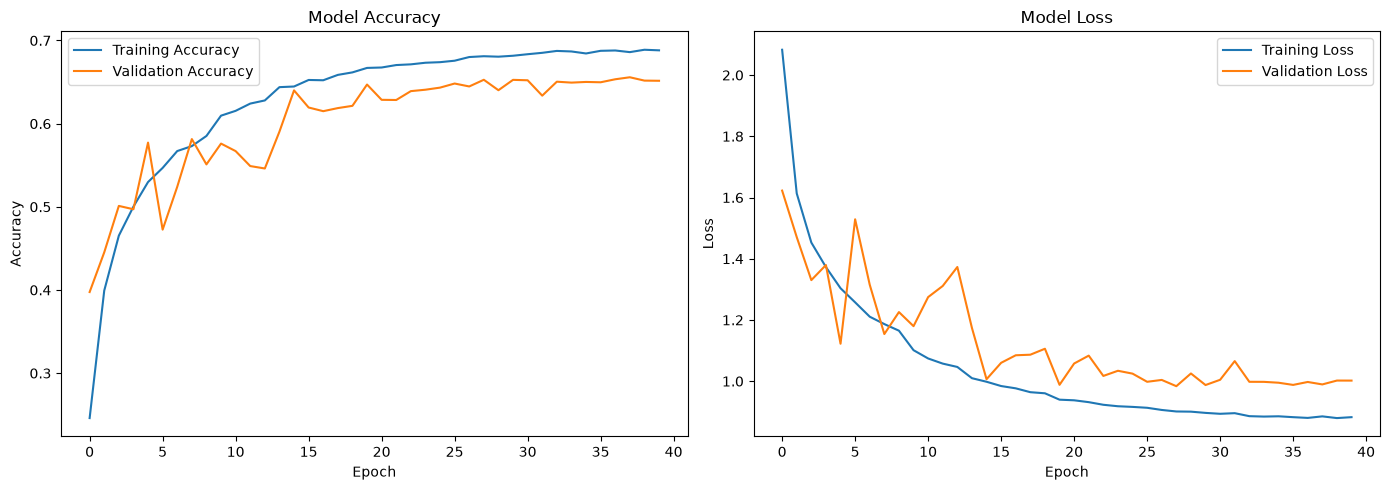

In [15]:
# Grafik akurasi dan loss
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(history["accuracy"], label="Training Accuracy")
plt.plot(history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy"); plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history["loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.title("Model Loss"); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "3_training_curves.png"), dpi=150)
plt.show()

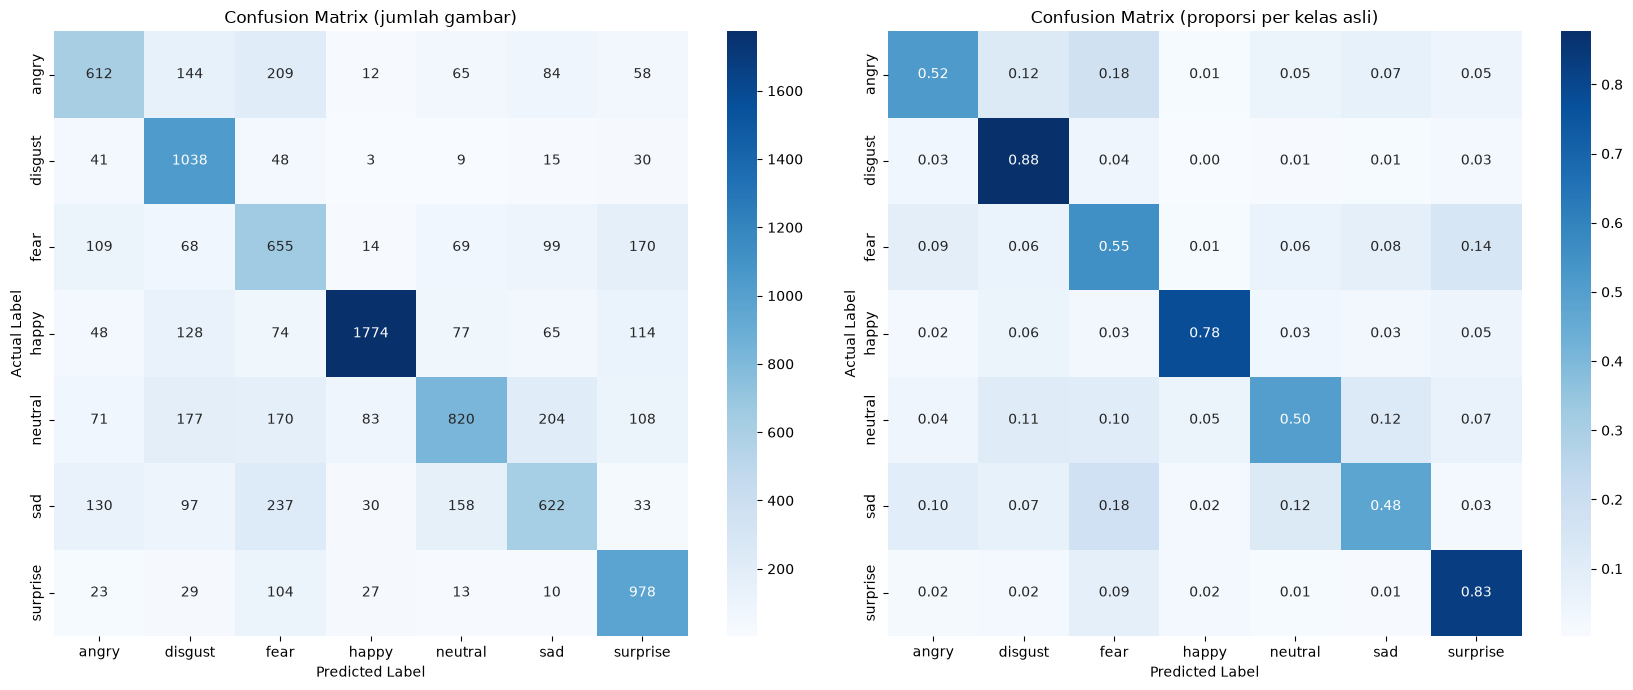

In [16]:
# Confusion matrix (jumlah dan ternormalisasi per baris)
cm = confusion_matrix(y_true, y_pred, labels=np.arange(num_classes))
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(os.path.join(OUT_DIR, "confusion_matrix.csv"))

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title("Confusion Matrix (jumlah gambar)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title("Confusion Matrix (proporsi per kelas asli)")
for a in axes:
    a.set_xlabel("Predicted Label"); a.set_ylabel("Actual Label")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "4_confusion_matrix.png"), dpi=150)
plt.show()

c:\Users\Axioo\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\models\functional.py:293: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_gray']
Received: inputs=Tensor(shape=(1, 48, 48, 1))
  warnings.warn(msg)


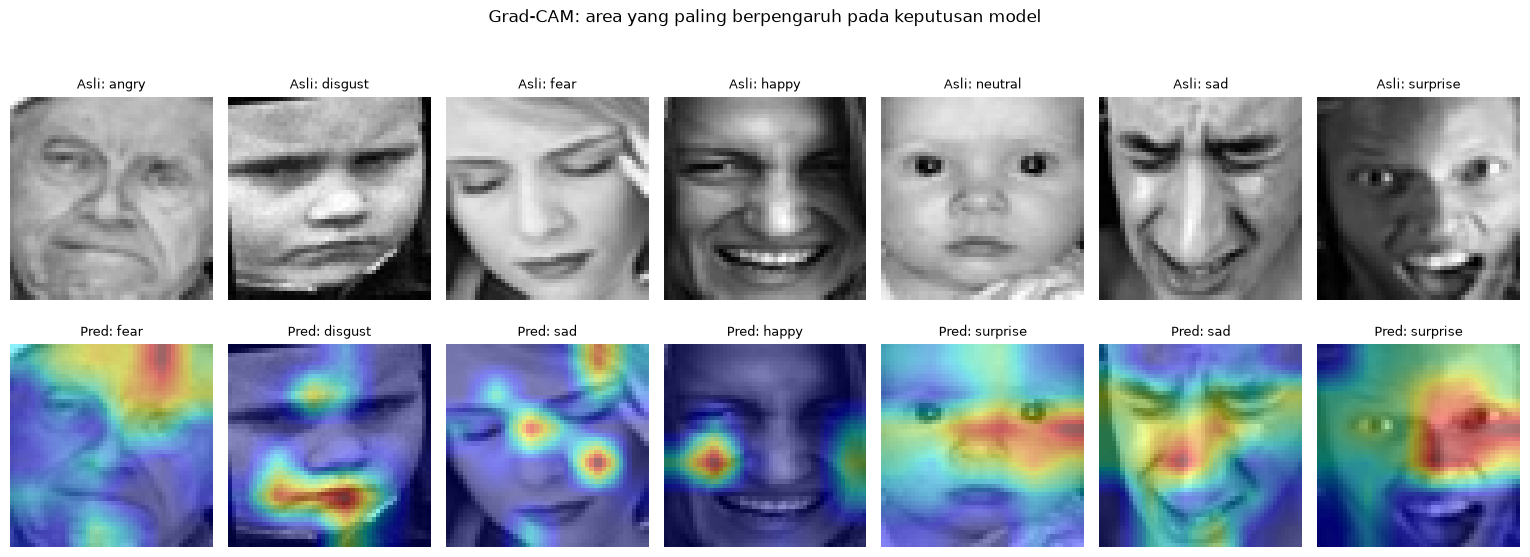

In [17]:
# Feature importance: Grad-CAM (area wajah yang paling memengaruhi keputusan model)
def make_gradcam(img_batch, model, layer_name="conv_last", class_idx=None):
    grad_model = tf.keras.Model(model.inputs, [model.get_layer(layer_name).output, model.output])
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(img_batch, training=False)
        if class_idx is None:
            class_idx = int(tf.argmax(preds[0]))
        score = preds[:, class_idx]
    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv_out[0] * weights, axis=-1))
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy(), class_idx, preds[0].numpy()

def load_gray48(path):
    return np.array(Image.open(path).convert("L").resize(IMG_SIZE), dtype=np.float32)

fig, axes = plt.subplots(2, num_classes, figsize=(2.2 * num_classes, 5.6))
for c in range(num_classes):
    idx = int(np.where(val_labels == c)[0][0])                 # satu contoh validasi per kelas
    img = load_gray48(val_paths[idx])
    cam, pred_idx, probs = make_gradcam(img[None, ..., None], model)
    cam_big = tf.image.resize(cam[..., None], IMG_SIZE).numpy().squeeze()
    axes[0, c].imshow(img, cmap="gray"); axes[0, c].axis("off")
    axes[0, c].set_title(f"Asli: {class_names[c]}", fontsize=9)
    axes[1, c].imshow(img, cmap="gray"); axes[1, c].imshow(cam_big, cmap="jet", alpha=0.45)
    axes[1, c].axis("off")
    axes[1, c].set_title(f"Pred: {class_names[pred_idx]}", fontsize=9)
plt.suptitle("Grad-CAM: area yang paling berpengaruh pada keputusan model", y=1.03)
plt.tight_layout(h_pad=2.0)
plt.savefig(os.path.join(OUT_DIR, "gradcam_visualization.png"), dpi=200, bbox_inches="tight")
plt.show()

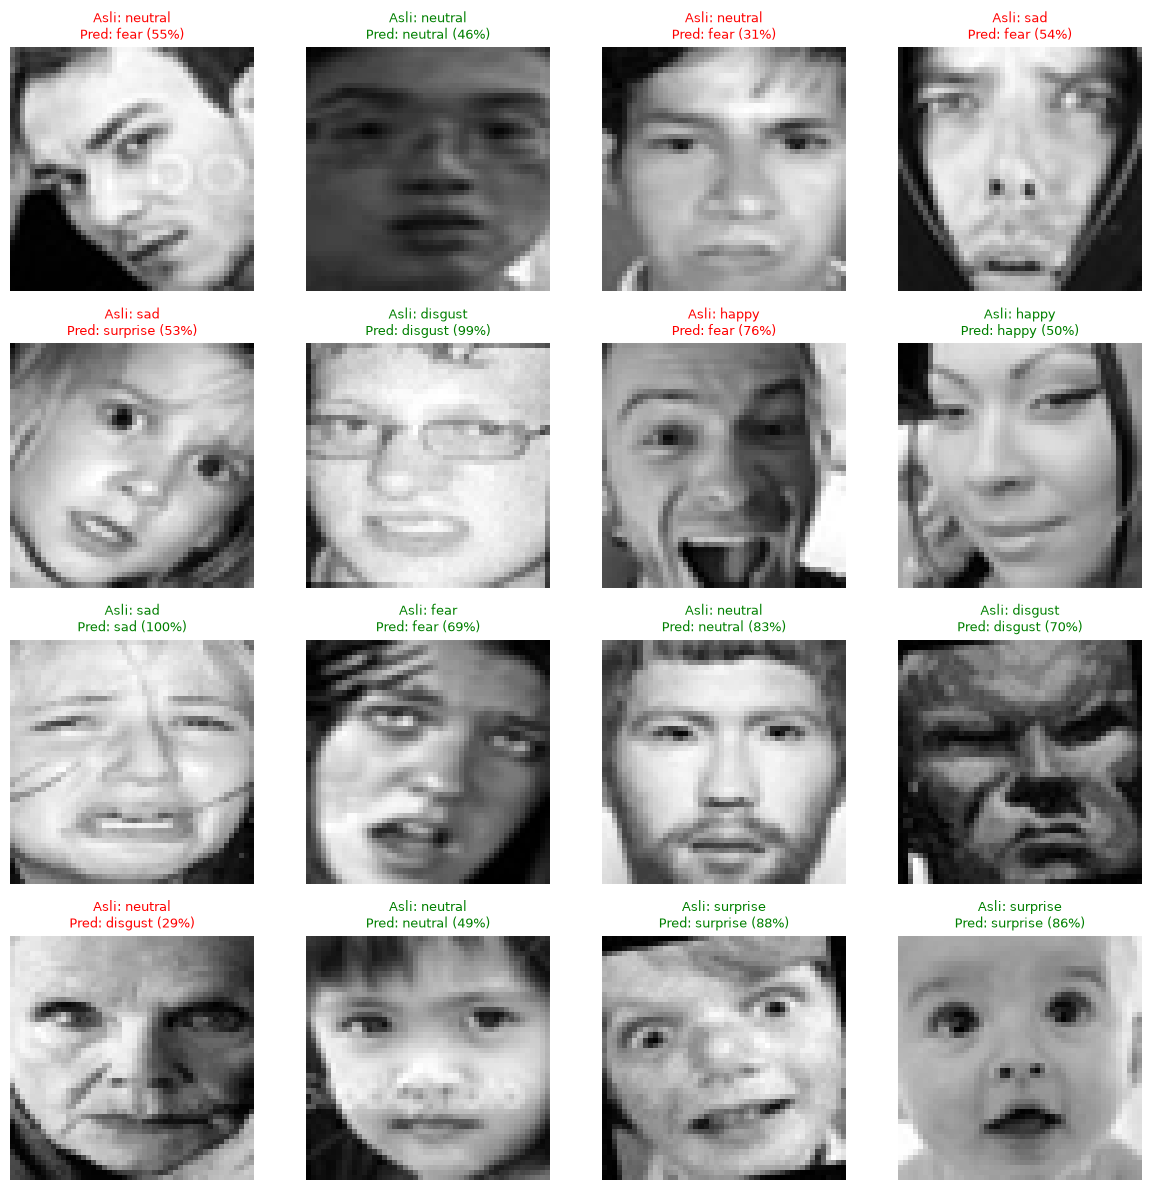

In [18]:
# Contoh hasil prediksi vs label asli (hijau = benar, merah = salah)
pick = np.random.default_rng(SEED).choice(len(val_paths), size=16, replace=False)
plt.figure(figsize=(12, 12))
for k, i in enumerate(pick):
    plt.subplot(4, 4, k + 1)
    plt.imshow(load_gray48(val_paths[i]), cmap="gray")
    ok = y_pred[i] == y_true[i]
    plt.title(f"Asli: {class_names[y_true[i]]}\nPred: {class_names[y_pred[i]]} ({y_prob[i].max():.0%})",
              fontsize=9, color="green" if ok else "red")
    plt.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "7_sample_predictions.png"), dpi=150)
plt.show()

## Langkah 7 - Simpan Model untuk Dashboard Streamlit
Model dan nama kelas disimpan ke folder `output/`, lalu dimuat ulang untuk memastikan hasilnya identik.

In [19]:
model.save(final_model_path)
with open(os.path.join(OUT_DIR, "class_names.json"), "w") as f:
    json.dump(class_names, f)
print("Model disimpan :", final_model_path)

loaded_model = tf.keras.models.load_model(final_model_path)
loaded_loss, loaded_acc = loaded_model.evaluate(val_ds, verbose=0)
print(f"Setelah dimuat ulang -> loss: {loaded_loss:.4f} | accuracy: {loaded_acc:.4f} (harus sama dengan hasil evaluasi di atas)")

Model disimpan : output\final_facial_emotion_cnn.keras
Setelah dimuat ulang -> loss: 0.9837 | accuracy: 0.6528 (harus sama dengan hasil evaluasi di atas)


### Uji prediksi gambar baru (pipeline yang sama dengan dashboard)
Cell berikut adalah **acuan preprocessing untuk `app.py`**. Hal yang membuat prediksi foto baru jelek biasanya ada di tahap ini:
1. Gambar harus dikonversi ke **grayscale 48x48** dan dikirim ke model sebagai **piksel 0-255** (tanpa dibagi 255 lagi)
2. Wajah harus di-**crop** dulu. Jika wajah tidak terdeteksi, ambil **crop persegi di tengah**, jangan di-*resize* langsung karena rasio gambar jadi gepeng
3. Pakai foto wajah yang **menghadap depan, utuh, dan cukup terang**

In [20]:
try:
    cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
    if cascade.empty():
        cascade = None
except Exception:
    cascade = None          # versi OpenCV tanpa Haar cascade -> otomatis pakai crop tengah
print("Detektor wajah Haar:", "aktif" if cascade is not None else "tidak tersedia (memakai crop tengah)")

def preprocess_face(pil_img, use_face_crop=True):
    rgb  = np.array(pil_img.convert("RGB"))
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    H, W = gray.shape
    crop, info = None, "Wajah tidak terdeteksi, memakai crop persegi di tengah gambar"
    if use_face_crop and cascade is not None:
        faces = cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40))
        if len(faces) > 0:
            x, y, w, h = max(faces, key=lambda f: f[2] * f[3])      # wajah terbesar
            m = int(0.10 * max(w, h))                                # margin 10%
            crop = gray[max(y - m, 0):min(y + h + m, H), max(x - m, 0):min(x + w + m, W)]
            info = "Wajah terdeteksi dan di-crop"
    if crop is None:
        s = min(H, W); y0, x0 = (H - s) // 2, (W - s) // 2
        crop = gray[y0:y0 + s, x0:x0 + s]
    face48 = cv2.resize(crop, IMG_SIZE, interpolation=cv2.INTER_AREA)   # tetap 0-255
    return face48, info

def predict_emotion(pil_img, model, use_face_crop=True, tta=True):
    face48, info = preprocess_face(pil_img, use_face_crop)
    x = face48.astype("float32")[None, ..., None]                        # JANGAN dibagi 255
    probs = model.predict(x, verbose=0)[0]
    if tta:                                                              # rata-rata dengan versi cermin
        probs = (probs + model.predict(x[:, :, ::-1, :], verbose=0)[0]) / 2
    return probs, face48, info

# Contoh: uji pada satu gambar validasi
test_path = val_paths[0]
probs, face48, info = predict_emotion(Image.open(test_path), loaded_model)
print(info)
print("Label asli :", class_names[val_labels[0]])
print("Prediksi   :", class_names[int(probs.argmax())], f"({probs.max():.2%})")
print({class_names[i]: round(float(p), 3) for i, p in enumerate(probs)})

Detektor wajah Haar: tidak tersedia (memakai crop tengah)
Wajah tidak terdeteksi, memakai crop persegi di tengah gambar
Label asli : sad
Prediksi   : sad (88.94%)
{'angry': 0.014, 'disgust': 0.033, 'fear': 0.045, 'happy': 0.01, 'neutral': 0.007, 'sad': 0.889, 'surprise': 0.001}


In [21]:
# Diagnosa: dampak kesalahan membagi 255 dua kali di app.py
x_ok  = face48.astype("float32")[None, ..., None]
x_bad = x_ok / 255.0
p_ok, p_bad = loaded_model.predict(x_ok, verbose=0)[0], loaded_model.predict(x_bad, verbose=0)[0]
print(f"Benar  (0-255)      -> {class_names[p_ok.argmax()]:9s} keyakinan {p_ok.max():.2%}")
print(f"Salah  (dibagi 255) -> {class_names[p_bad.argmax()]:9s} keyakinan {p_bad.max():.2%}   <- terjadi jika app.py ikut membagi 255")

Benar  (0-255)      -> sad       keyakinan 92.00%
Salah  (dibagi 255) -> sad       keyakinan 51.21%   <- terjadi jika app.py ikut membagi 255


## Langkah 8 - Bahan Laporan
Seluruh gambar dan tabel untuk laporan ada di folder `output/`:
`1_class_distribution.png`, `2_sample_images.png`, `3_training_curves.png`, `4_confusion_matrix.png`, `5_evaluation_metrics.png`, `gradcam_visualization.png`, `7_sample_predictions.png`, `classification_report.csv`, `evaluation_metrics.csv`.

Jalankan dashboard dengan: `streamlit run app.py` lalu ambil tangkapan layar tiap tab.